In [1]:
from fastai.collab import *
from fastai.tabular.all import *

In [2]:
movies_path = "./data/movies.csv"
ratings_path = "./data/ratings.csv"

In [3]:
movies_df = pd.read_csv(movies_path)
ratings_df = pd.read_csv(ratings_path)

In [4]:
ratings_df = ratings_df.merge(movies_df)

In [5]:
ratings_df.head()

,userId,movieId,rating,timestamp,title,genres
0,1,296,5.0,1147880044,Pulp Fiction (1994),Comedy|Crime|Drama|Thriller
1,1,306,3.5,1147868817,Three Colors: Red (Trois couleurs: Rouge) (1994),Drama
2,1,307,5.0,1147868828,Three Colors: Blue (Trois couleurs: Bleu) (1993),Drama
3,1,665,5.0,1147878820,Underground (1995),Comedy|Drama|War
4,1,899,3.5,1147868510,Singin' in the Rain (1952),Comedy|Musical|Romance


In [6]:
movie_value_counts = ratings_df.movieId.value_counts()
movie_value_counts

movieId
356       81491
318       81482
296       79672
593       74127
2571      72674
          ...  
150198        1
150206        1
150212        1
150304        1
150088        1
Name: count, Length: 59047, dtype: int64

In [7]:
ratings_df = ratings_df[
    ratings_df['movieId'].isin(movie_value_counts[movie_value_counts >= 5].index)
]

In [8]:
dls = CollabDataLoaders.from_df(ratings_df, item_name="title", bs=50000)

In [9]:
dls.show_batch()

,userId,title,rating
0,86357,Wedding Crashers (2005),2.5
1,1686,From Dusk Till Dawn (1996),3.0
2,102107,"Big Lebowski, The (1998)",2.0
3,136971,Lethal Weapon 2 (1989),3.0
4,134814,"Doors, The (1991)",3.0
5,40028,Toy Story 3 (2010),2.0
6,40811,Not Without My Daughter (1991),5.0
7,139238,Who Framed Roger Rabbit? (1988),3.0
8,154090,Pulp Fiction (1994),5.0
9,42304,Three Colors: White (Trzy kolory: Bialy) (1994),5.0


In [9]:
len(ratings_df)

24945870

In [10]:
embs = get_emb_sz(dls)
embs

[(162542, 600), (32685, 540)]

In [27]:
emb_szs={'userId': 300, 'title': 300}

In [33]:
learn = collab_learner(dls, use_nn=True, y_range=(0, 5.5), layers=[100, 50], emb_szs=emb_szs)

SuggestedLRs(valley=0.00013182566908653826)

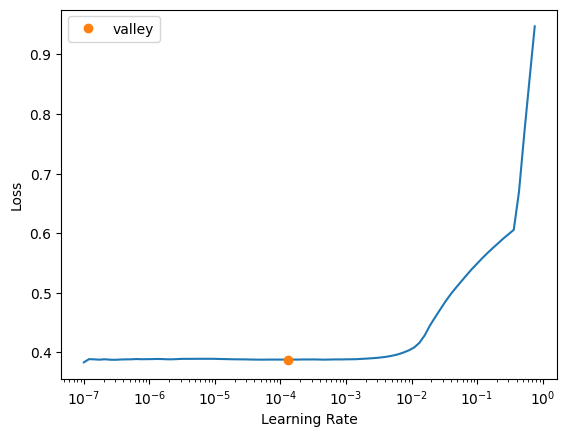

In [38]:
learn.lr_find()

1) tweak layers
2) Have to achieve around 0.3 loss
3) train longer
4) tweak weight decay

In [ ]:
learn.fit_one_cycle(5, 1e-4, wd=0.01)

epoch,train_loss,valid_loss,time
0,0.382791,0.732849,00:50
1,0.367249,0.742738,00:46
2,0.353184,0.749586,00:46
3,0.344059,0.753507,00:44
4,0.341722,0.754176,00:45


: 